# Практическая работа №4. Разработка и сравнительный анализ моделей кластеризации
**Вариант 5.** Датасет: Supermarket Sales (Kaggle). Предметная область: торговля. Особенность: использовать только числовые признаки. Модели: KMeans, DBSCAN.

## Этап 1. Подбор и загрузка датасета

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
import os; os.makedirs('fig', exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(f'fig/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

URL = 'https://raw.githubusercontent.com/selva86/datasets/master/supermarket_sales.csv'
if not os.path.exists('supermarket_sales.csv'):   # в Colab датасет скачивается автоматически
    pd.read_csv(URL).to_csv('supermarket_sales.csv', index=False)
df = pd.read_csv('supermarket_sales.csv')
print('Количество объектов:', df.shape[0])
print('Количество признаков:', df.shape[1])

Количество объектов: 1000
Количество признаков: 17


In [2]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print('Типы данных:'); print(df.dtypes)
print('\nЧисловые признаки (%d):' % len(num_cols), num_cols)
print('Категориальные признаки (%d):' % len(cat_cols), cat_cols)

Типы данных:
Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object

Числовые признаки (8): ['Unit price', 'Quantity', 'Tax 5%', 'Total', 'cogs', 'gross margin percentage', 'gross income', 'Rating']
Категориальные признаки (9): ['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Date', 'Time', 'Payment']


Целевая переменная в датасете отсутствует: задача кластеризации решается без учителя. Категориальные признаки (Branch, City, Product line и др.) по условию варианта в обучении не используются, а применяются только для интерпретации кластеров.

## Этап 2. Исследовательский анализ данных (EDA)

In [3]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:
df.tail()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1/29/2019,13:46,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3/2/2019,17:16,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2/9/2019,13:22,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2/22/2019,15:33,Cash,65.82,4.761905,3.2910,4.1
999,849-09-3807,A,Yangon,Member,Female,Fashion accessories,88.34,7,30.9190,649.2990,2/18/2019,13:28,Cash,618.38,4.761905,30.9190,6.6


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  1000 non-nu

In [6]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Unit price,1000.0,55.672,26.495,10.080,32.875,55.230,77.935,99.960
Quantity,1000.0,5.510,2.923,1.000,3.000,5.000,8.000,10.000
Tax 5%,1000.0,15.379,11.709,0.508,5.925,12.088,22.445,49.650
Total,1000.0,322.967,245.885,10.678,124.422,253.848,471.350,1042.650
cogs,1000.0,307.587,234.177,10.170,118.498,241.760,448.905,993.000
gross margin percentage,1000.0,4.762,0.000,4.762,4.762,4.762,4.762,4.762
gross income,1000.0,15.379,11.709,0.508,5.925,12.088,22.445,49.650
Rating,1000.0,6.973,1.719,4.000,5.500,7.000,8.500,10.000


In [7]:
print('Пропущенные значения:'); print(df.isna().sum())
print('\nКоличество дубликатов:', df.duplicated().sum())
print('Дубликатов Invoice ID:', df['Invoice ID'].duplicated().sum())

Пропущенные значения:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Количество дубликатов: 0
Дубликатов Invoice ID: 0


In [8]:
print('Асимметрия (skew):'); print(df[num_cols].skew().round(3))
print('\nКоличество уникальных значений:'); print(df[num_cols].nunique())

Асимметрия (skew):
Unit price                 0.007
Quantity                   0.013
Tax 5%                     0.893
Total                      0.893
cogs                       0.893
gross margin percentage    0.000
gross income               0.893
Rating                     0.009
dtype: float64

Количество уникальных значений:
Unit price                 943
Quantity                    10
Tax 5%                     990
Total                      990
cogs                       990
gross margin percentage      1
gross income               990
Rating                      61
dtype: int64


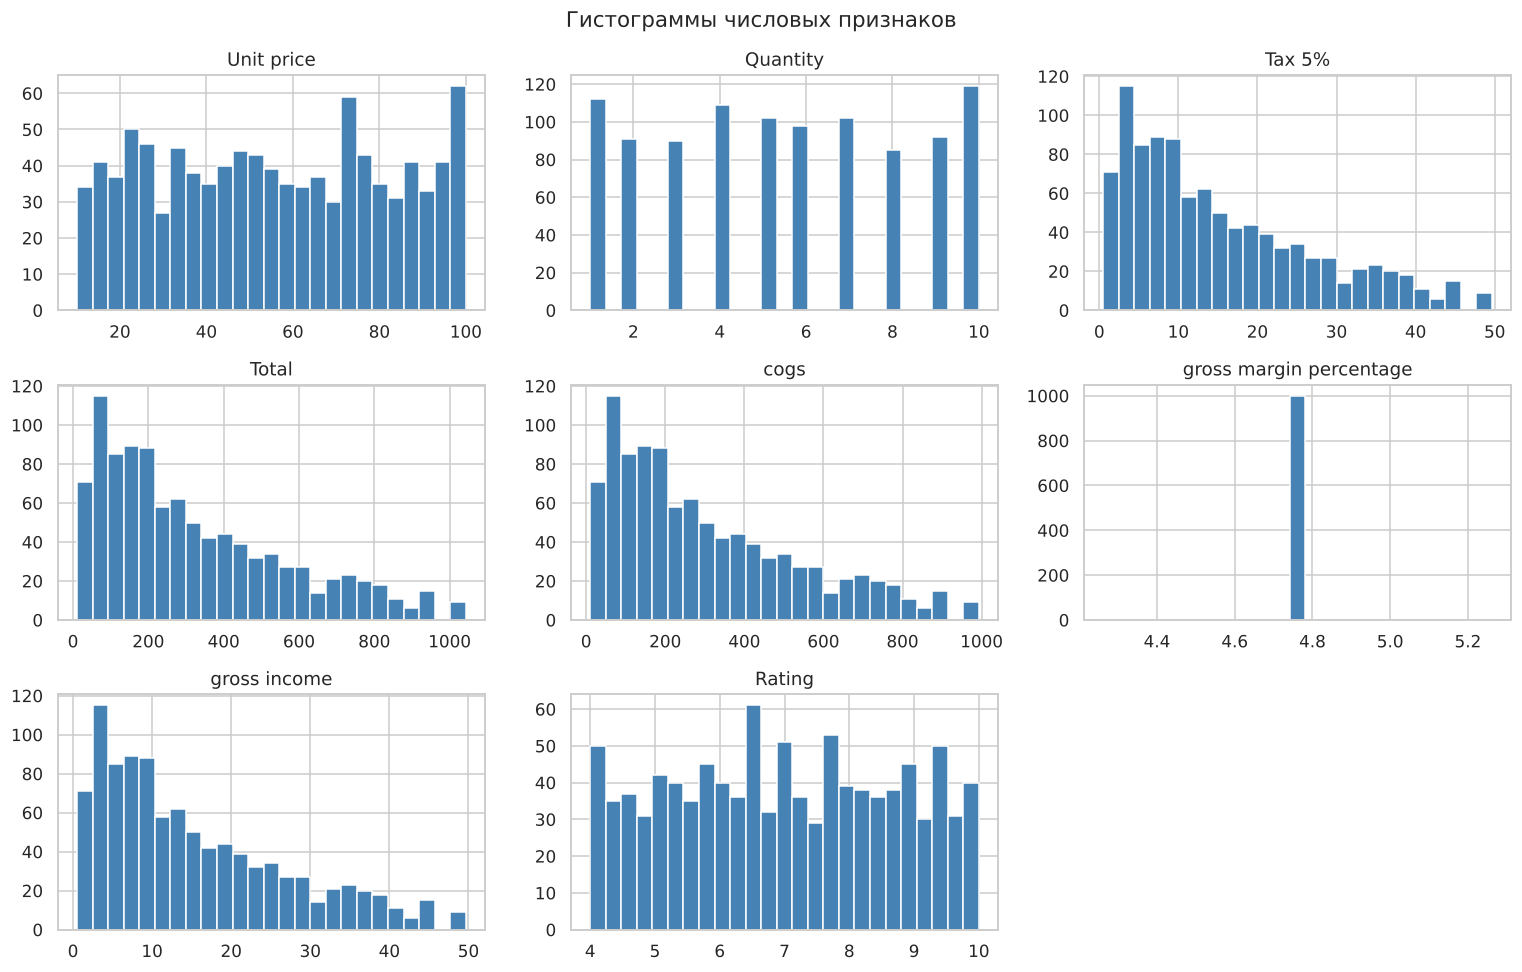

In [9]:
df[num_cols].hist(bins=25, figsize=(14, 9), color='steelblue', edgecolor='white')
plt.suptitle('Гистограммы числовых признаков', fontsize=14)
save('hist')

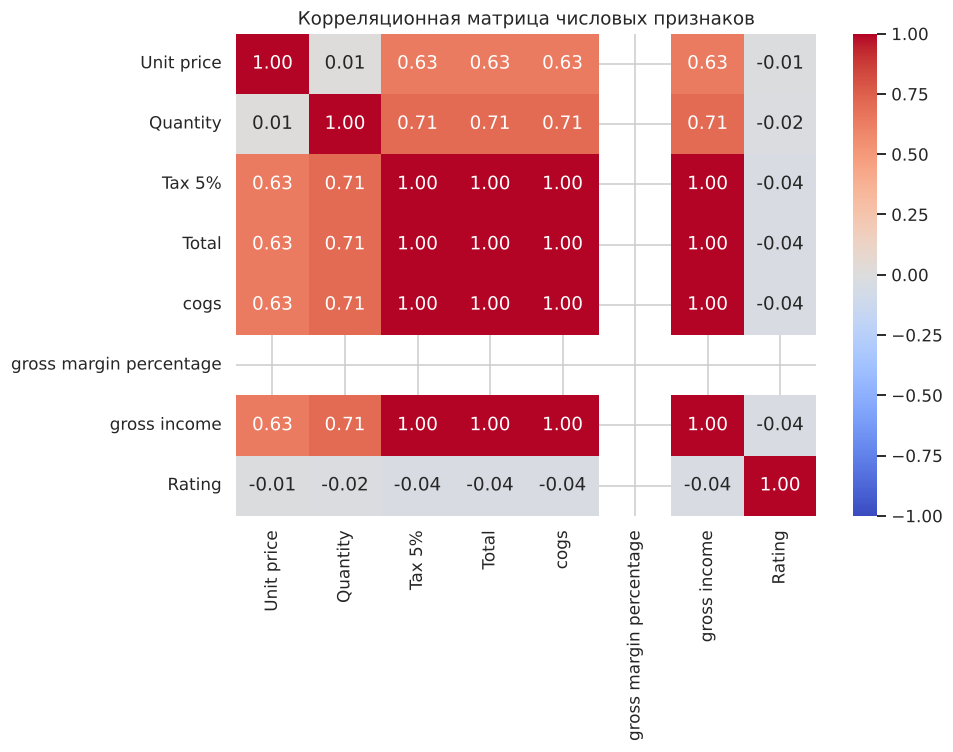

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
save('corr')

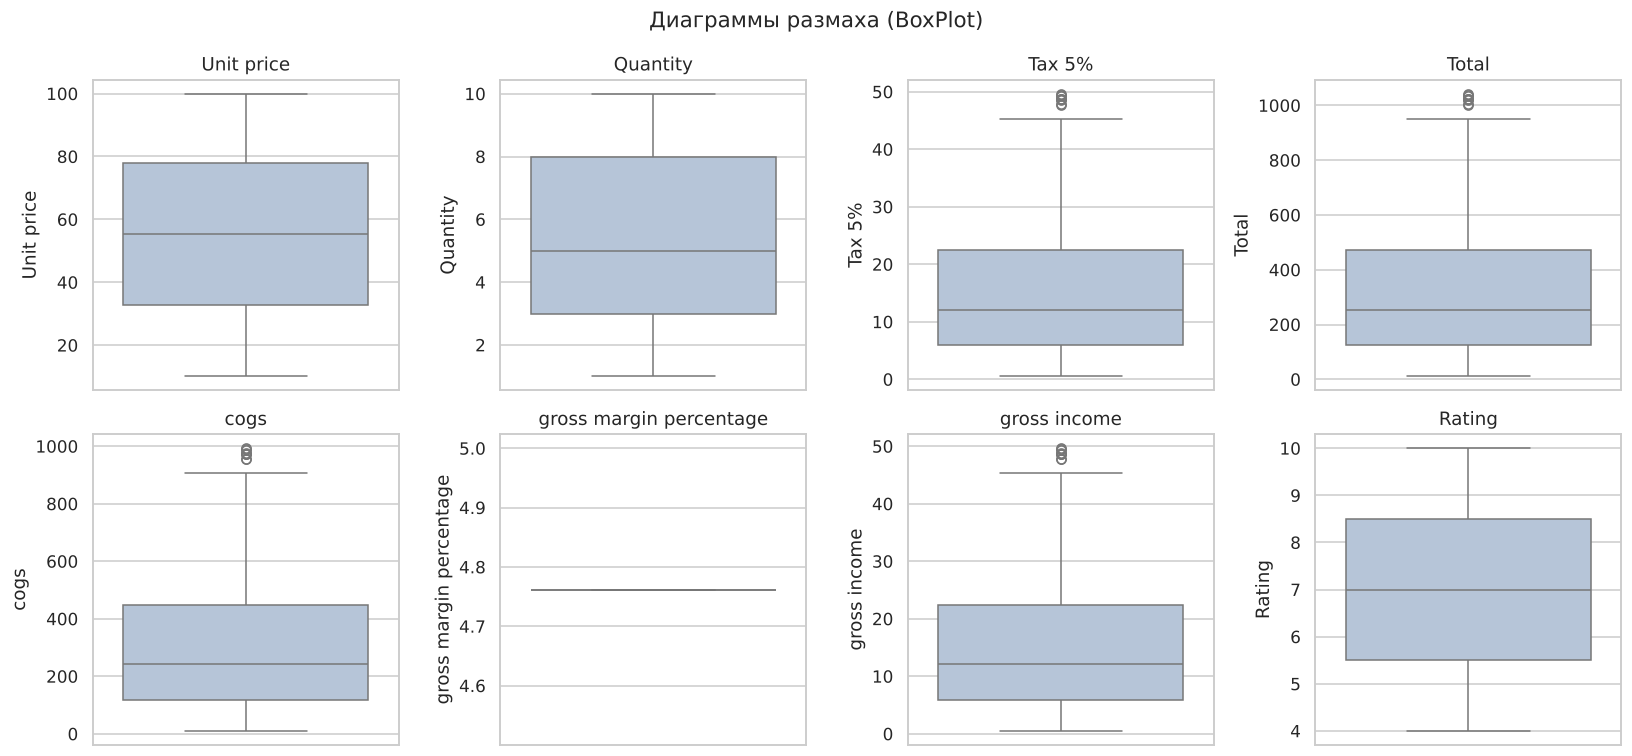

Выбросы по правилу 1.5·IQR:
Unit price                 0
Quantity                   0
Tax 5%                     9
Total                      9
cogs                       9
gross margin percentage    0
gross income               9
Rating                     0
dtype: int64


In [11]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color='lightsteelblue'); ax.set_title(c)
plt.suptitle('Диаграммы размаха (BoxPlot)', fontsize=14)
save('box')
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()
print('Выбросы по правилу 1.5·IQR:'); print(df[num_cols].apply(iqr_out))

**Выводы по EDA.** Данные корректны: 1000 записей, 17 признаков, пропусков и дубликатов нет. Признак `gross margin percentage` постоянен (одно значение) и неинформативен. Признаки `Tax 5%`, `Total`, `cogs` и `gross income` попарно коррелируют с коэффициентом 1.00, так как вычисляются из `Unit price × Quantity`. Это избыточные признаки: они завышают вес «суммы чека» в расстояниях. Небольшое число выбросов есть только у денежных признаков (крупные чеки); это реальные покупки, а не ошибки. Признаки измеряются в разных шкалах, поэтому нужно масштабирование.

## Этап 3. Предварительная обработка данных

In [12]:
df = df.drop_duplicates()
print('После удаления дубликатов:', df.shape)
print('Пропусков:', int(df.isna().sum().sum()), '— обработка не требуется')

После удаления дубликатов: (1000, 17)
Пропусков: 0 — обработка не требуется


In [13]:
# По условию варианта используем только числовые признаки
X_num = df[num_cols].copy()
# Удаляем константный признак
X_num = X_num.drop(columns=['gross margin percentage'])
# Удаляем линейно зависимые признаки (корреляция = 1 с Total)
X_num = X_num.drop(columns=['Tax 5%', 'cogs', 'gross income'])
features = X_num.columns.tolist()
print('Признаки для кластеризации:', features)

Признаки для кластеризации: ['Unit price', 'Quantity', 'Total', 'Rating']


Выбросы не удаляются: это реальные крупные покупки, они важны для сегментации, а их немного. DBSCAN при этом сам отметит нетипичные объекты как шум. Кодирование категориальных признаков не требуется (используются только числовые). Целевой переменной нет.

In [14]:
scaler = StandardScaler()
X = scaler.fit_transform(X_num)
pd.DataFrame(X, columns=features).describe().T[['mean','std']].round(3)

,mean,std
Unit price,-0.0,1.001
Quantity,0.0,1.001
Total,0.0,1.001
Rating,0.0,1.001


После стандартизации каждый признак имеет среднее 0 и стандартное отклонение 1, поэтому признаки вносят сопоставимый вклад в расстояние.

## Этап 4. Определение параметров кластеризации

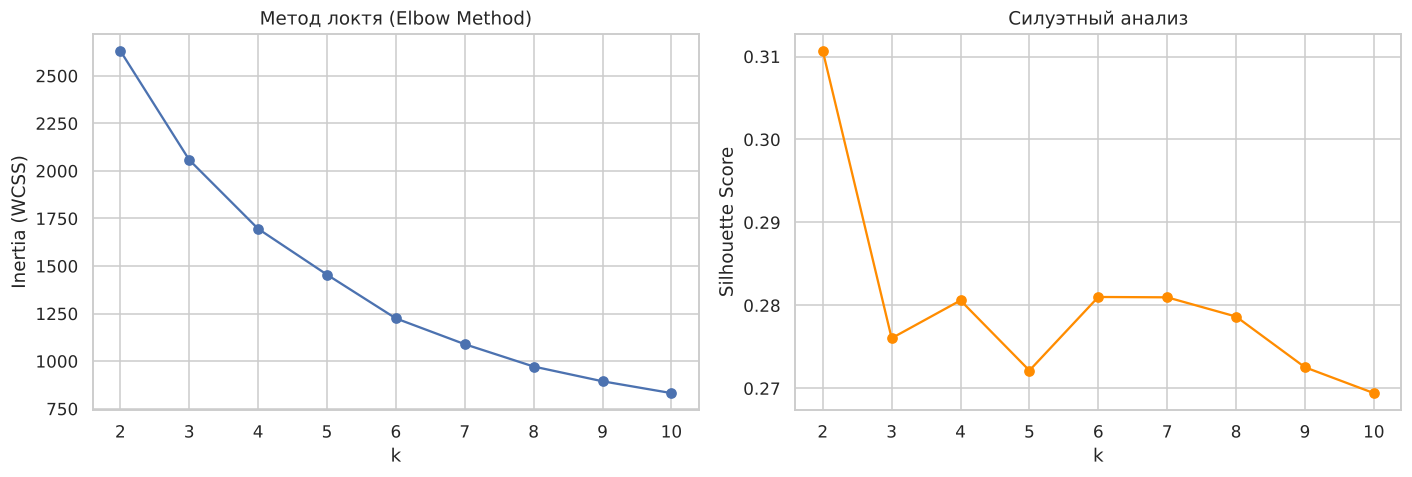

 k  Inertia  Silhouette
 2   2631.4      0.3107
 3   2058.2      0.2760
 4   1695.9      0.2806
 5   1454.8      0.2722
 6   1224.9      0.2810
 7   1089.3      0.2810
 8    971.8      0.2787
 9    894.3      0.2725
10    832.1      0.2694


In [15]:
ks = range(2, 11); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, inertia, 'o-'); ax[0].set(title='Метод локтя (Elbow Method)', xlabel='k', ylabel='Inertia (WCSS)')
ax[1].plot(ks, sil, 'o-', color='darkorange'); ax[1].set(title='Силуэтный анализ', xlabel='k', ylabel='Silhouette Score')
save('elbow')
print(pd.DataFrame({'k': list(ks), 'Inertia': np.round(inertia, 1), 'Silhouette': np.round(sil, 4)}).to_string(index=False))

In [16]:
BEST_K = int(list(ks)[int(np.argmax(sil))])
print('Выбранное число кластеров k =', BEST_K)

Выбранное число кластеров k = 2


Для DBSCAN параметр `min_samples` выбран по правилу `2 × число признаков` = 8. Значение `eps` определяется по графику k-расстояний (расстояние до 8-го соседа): ищется «излом» кривой. Затем перебираются значения в его окрестности.

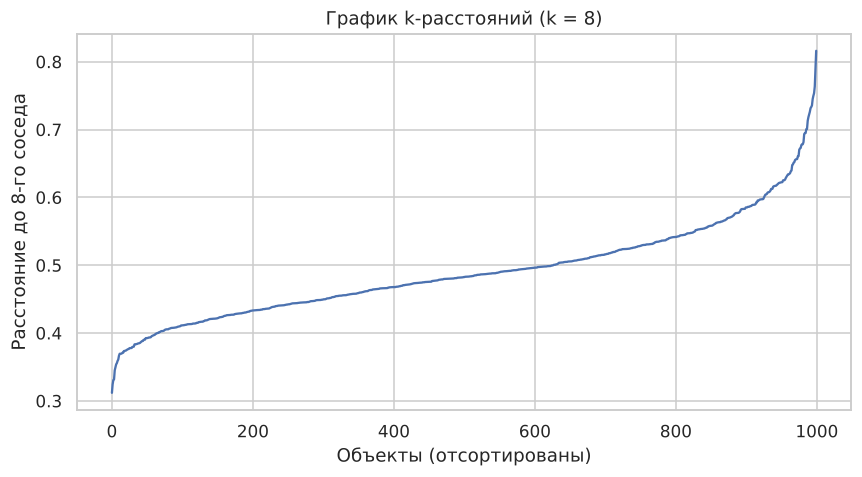

  eps  Кластеров  Шум, %  Silhouette (без шума)
0.300          0   100.0                    NaN
0.325          1    99.0                    NaN
0.350          4    96.5                 0.6611
0.375         10    90.0                 0.6435
0.400         16    74.8                 0.3279
0.425         25    54.4                 0.1343
0.450         22    34.8                -0.0618
0.475         12    19.6                -0.2204
0.500          5     7.9                -0.0008
0.525          4     3.3                 0.0146
0.550          1     1.0                    NaN
0.575          1     0.4                    NaN
0.600          1     0.2                    NaN
0.625          1     0.0                    NaN
0.650          1     0.0                    NaN
0.675          1     0.0                    NaN
0.700          1     0.0                    NaN
0.725          1     0.0                    NaN
0.750          1     0.0                    NaN
0.775          1     0.0                

In [17]:
MIN_SAMPLES = 2 * X.shape[1]
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
d = np.sort(nn.kneighbors(X)[0][:, -1])
plt.figure(figsize=(8, 4.5)); plt.plot(d)
plt.title(f'График k-расстояний (k = {MIN_SAMPLES})'); plt.xlabel('Объекты (отсортированы)'); plt.ylabel(f'Расстояние до {MIN_SAMPLES}-го соседа')
save('kdist')
rows = []
for eps in np.round(np.arange(0.3, 1.01, 0.025), 3):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    n_cl = len(set(lab)) - (-1 in lab); noise = (lab == -1).mean()
    m = lab != -1
    s = silhouette_score(X[m], lab[m]) if n_cl >= 2 else np.nan
    rows.append((eps, n_cl, round(noise*100, 1), round(s, 4) if s == s else s))
grid = pd.DataFrame(rows, columns=['eps', 'Кластеров', 'Шум, %', 'Silhouette (без шума)'])
grid.to_csv('dbscan_grid.csv', index=False)
print(grid.to_string(index=False))

In [18]:
ok = grid[(grid['Кластеров'] >= 2) & (grid['Шум, %'] <= 10)]
BEST_EPS = float(ok.sort_values('Silhouette (без шума)', ascending=False).iloc[0]['eps']) if len(ok) else 1.0
print('Выбранные параметры DBSCAN: eps =', BEST_EPS, ', min_samples =', MIN_SAMPLES)

Выбранные параметры DBSCAN: eps = 0.525 , min_samples = 8


## Этап 5. Построение и обучение моделей

In [19]:
t0 = time.perf_counter()
kmeans = KMeans(n_clusters=BEST_K, n_init=20, random_state=42).fit(X)
t_km = time.perf_counter() - t0
df['KMeans'] = kmeans.labels_

t0 = time.perf_counter()
dbscan = DBSCAN(eps=BEST_EPS, min_samples=MIN_SAMPLES).fit(X)
t_db = time.perf_counter() - t0
df['DBSCAN'] = dbscan.labels_
print(f'KMeans обучен за {t_km*1000:.1f} мс, DBSCAN за {t_db*1000:.1f} мс')
df[['KMeans', 'DBSCAN']].to_csv('clusters_result.csv', index=False)
df[features + ['KMeans', 'DBSCAN']].head()

KMeans обучен за 45.5 мс, DBSCAN за 9.1 мс


,Unit price,Quantity,Total,Rating,KMeans,DBSCAN
0,74.69,7,548.9715,9.1,0,0
1,15.28,5,80.2200,9.6,1,0
2,46.33,7,340.5255,7.4,1,0
3,58.22,8,489.0480,8.4,0,0
4,86.31,7,634.3785,5.3,0,0


## Этап 6. Оценка качества моделей

In [20]:
def metrics(lab, Xm=X):
    m = lab != -1
    return [len(set(lab[m])), int((~m).sum()),
            silhouette_score(Xm[m], lab[m]), calinski_harabasz_score(Xm[m], lab[m]), davies_bouldin_score(Xm[m], lab[m])]
res = pd.DataFrame([metrics(kmeans.labels_) + [t_km*1000], metrics(dbscan.labels_) + [t_db*1000]],
                   index=['KMeans', 'DBSCAN'],
                   columns=['Кластеров', 'Шум (объектов)', 'Silhouette ↑', 'Calinski–Harabasz ↑', 'Davies–Bouldin ↓', 'Время, мс'])
res.round(3).to_csv('metrics.csv')
res.round(3)

,Кластеров,Шум (объектов),Silhouette ↑,Calinski–Harabasz ↑,Davies–Bouldin ↓,"Время, мс"
KMeans,2,0,0.311,519.077,1.262,45.450
DBSCAN,4,33,0.015,93.857,1.000,9.138


Для DBSCAN метрики рассчитаны по объектам без шума (метка −1).

In [21]:
print('KMeans — объектов в кластерах:'); print(df['KMeans'].value_counts().sort_index())
print('\nDBSCAN — объектов в кластерах (-1 = шум):'); print(df['DBSCAN'].value_counts().sort_index())

KMeans — объектов в кластерах:
KMeans
0    364
1    636
Name: count, dtype: int64

DBSCAN — объектов в кластерах (-1 = шум):
DBSCAN
-1     33
 0    856
 1     89
 2     20
 3      2
Name: count, dtype: int64


In [22]:
print('Профили кластеров KMeans (средние значения):')
prof = df.groupby('KMeans')[features].mean().round(2); prof['Размер'] = df['KMeans'].value_counts().sort_index(); prof

Профили кластеров KMeans (средние значения):


,Unit price,Quantity,Total,Rating,Размер
KMeans,,,,,
0,73.99,7.88,598.21,6.88,364
1,45.19,4.16,165.44,7.02,636


In [23]:
print('Профили кластеров DBSCAN (средние значения):')
prof2 = df.groupby('DBSCAN')[features].mean().round(2); prof2['Размер'] = df['DBSCAN'].value_counts().sort_index(); prof2

Профили кластеров DBSCAN (средние значения):


,Unit price,Quantity,Total,Rating,Размер
DBSCAN,,,,,
-1,86.64,6.55,578.64,7.24,33
0,51.13,4.98,253.00,6.98,856
1,81.26,9.22,780.78,6.33,89
2,83.59,9.50,831.29,9.23,20
3,70.91,8.00,595.64,6.30,2


## Этап 7. Визуализация результатов

Доля объяснённой дисперсии PC1+PC2: 0.739


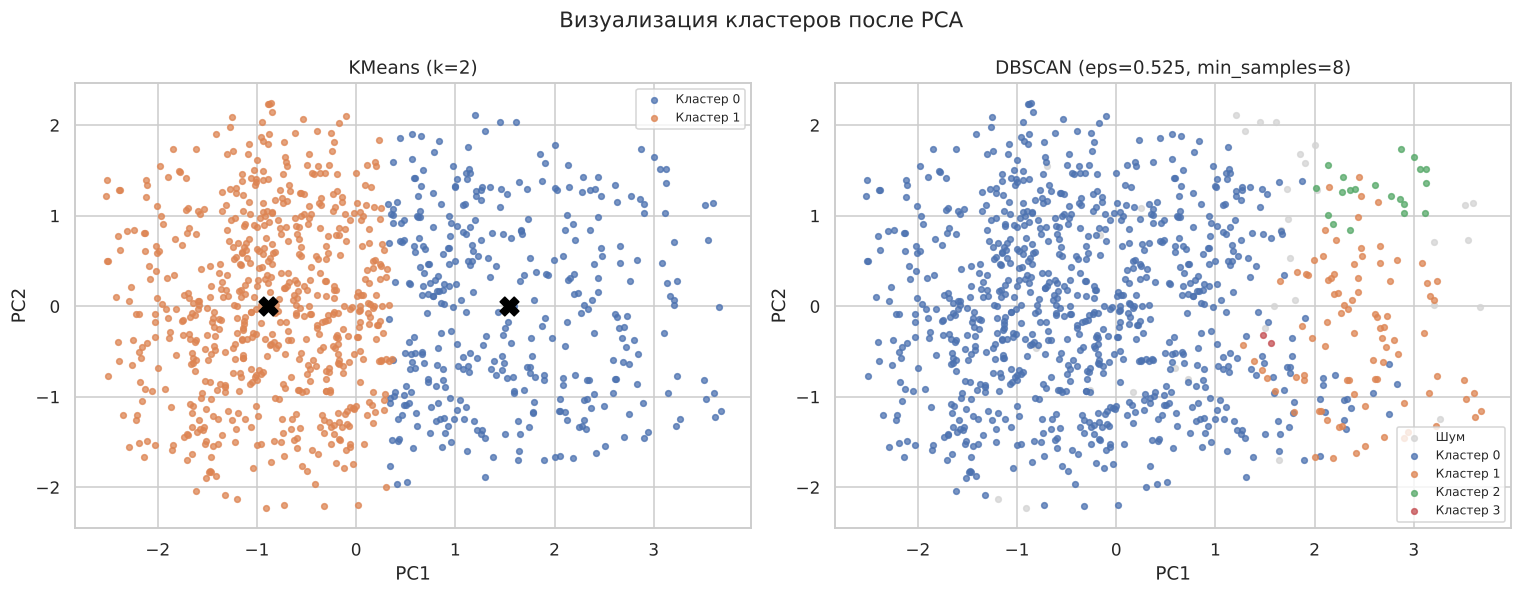

In [24]:
pca = PCA(n_components=2, random_state=42); P = pca.fit_transform(X)
print('Доля объяснённой дисперсии PC1+PC2:', pca.explained_variance_ratio_.sum().round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, col, t in [(ax[0], 'KMeans', f'KMeans (k={BEST_K})'), (ax[1], 'DBSCAN', f'DBSCAN (eps={BEST_EPS}, min_samples={MIN_SAMPLES})')]:
    lab = df[col].values
    for c in sorted(set(lab)):
        m = lab == c
        a.scatter(P[m, 0], P[m, 1], s=14, alpha=.75, label='Шум' if c == -1 else f'Кластер {c}', c='lightgrey' if c == -1 else None)
    a.set(title=t, xlabel='PC1', ylabel='PC2'); a.legend(fontsize=8)
if hasattr(kmeans, 'cluster_centers_'):
    cp = pca.transform(kmeans.cluster_centers_); ax[0].scatter(cp[:, 0], cp[:, 1], c='black', marker='X', s=150)
plt.suptitle('Визуализация кластеров после PCA', fontsize=14)
save('pca')

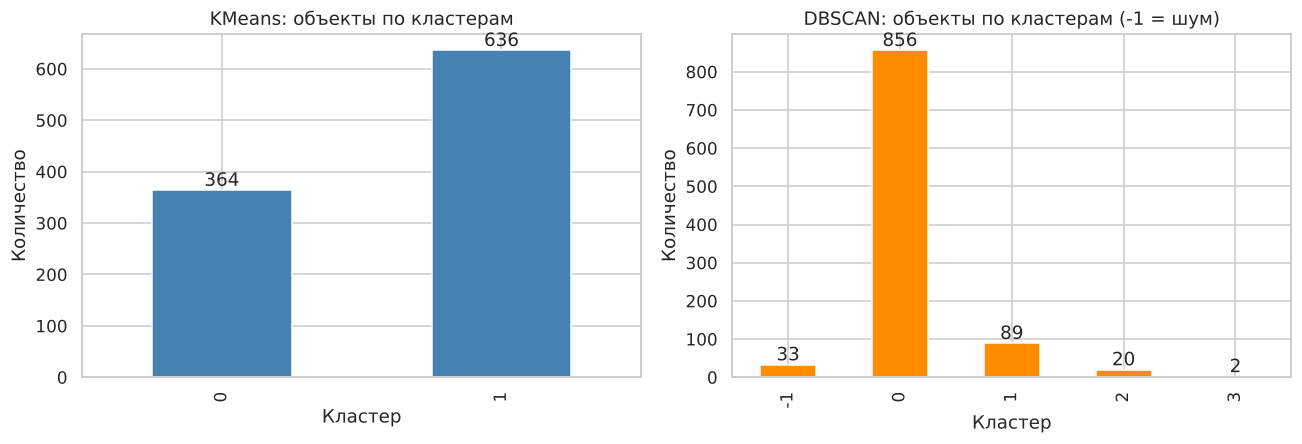

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
df['KMeans'].value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue'); ax[0].set(title='KMeans: объекты по кластерам', xlabel='Кластер', ylabel='Количество')
df['DBSCAN'].value_counts().sort_index().plot.bar(ax=ax[1], color='darkorange'); ax[1].set(title='DBSCAN: объекты по кластерам (-1 = шум)', xlabel='Кластер', ylabel='Количество')
for a in ax:
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
save('sizes')

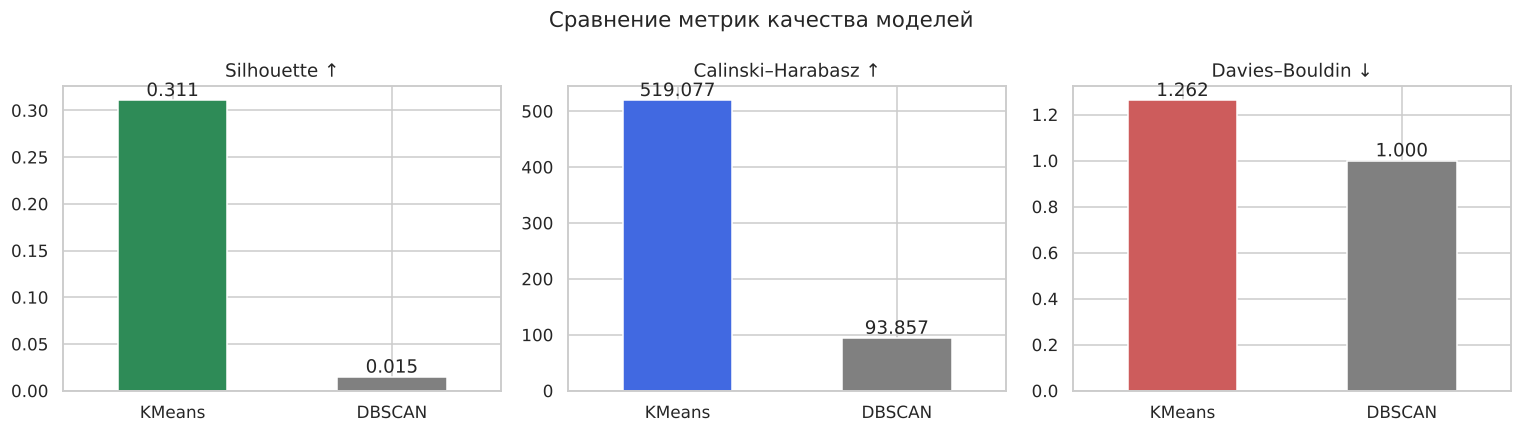

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, m, col in zip(ax, ['Silhouette ↑', 'Calinski–Harabasz ↑', 'Davies–Bouldin ↓'], ['seagreen', 'royalblue', 'indianred']):
    res[m].plot.bar(ax=a, color=[col, 'grey']); a.set_title(m); a.tick_params(axis='x', rotation=0)
    for p in a.patches: a.annotate(f'{p.get_height():.3f}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.suptitle('Сравнение метрик качества моделей', fontsize=14)
save('metrics')

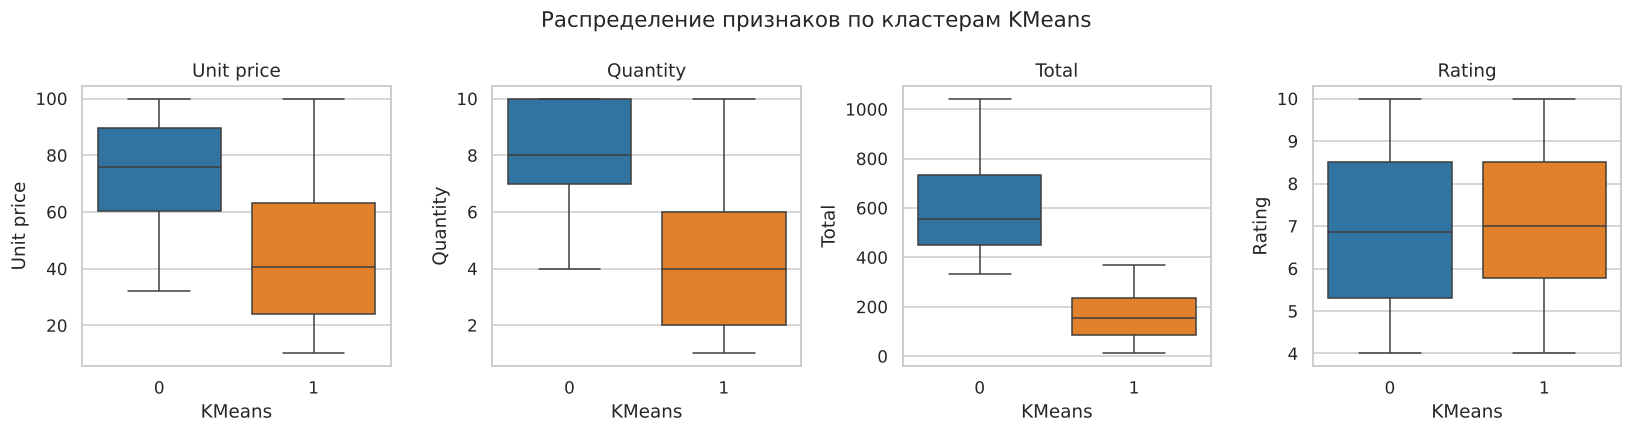

In [27]:
fig, ax = plt.subplots(1, len(features), figsize=(15, 4))
for a, f in zip(ax, features):
    sns.boxplot(data=df, x='KMeans', y=f, ax=a, palette='tab10'); a.set_title(f)
plt.suptitle('Распределение признаков по кластерам KMeans', fontsize=14)
save('profile')

## Этап 8. Сравнение моделей

In [28]:
better = lambda col, hi=True: res[col].idxmax() if hi else res[col].idxmin()
print('Лучшая по Silhouette:', better('Silhouette ↑'))
print('Лучшая по Calinski–Harabasz:', better('Calinski–Harabasz ↑'))
print('Лучшая по Davies–Bouldin:', better('Davies–Bouldin ↓', False))
print('Кластеров: KMeans =', res.loc['KMeans','Кластеров'], ', DBSCAN =', res.loc['DBSCAN','Кластеров'], '+ шум', res.loc['DBSCAN','Шум (объектов)'])

Лучшая по Silhouette: KMeans
Лучшая по Calinski–Harabasz: KMeans
Лучшая по Davies–Bouldin: DBSCAN
Кластеров: KMeans = 2 , DBSCAN = 4 + шум 33
